# Week 6 — National Grid Integration Checkpoint
**Name:** Hashim Nadeem  
**Roll No:** SU92-BDSFM-F25-001  
**Section:** BS DS-7a  
**Course:** CDB601220

Completed Tasks A, B, C and bonus D1. All data are synthetic. This notebook contains the full processing and plotting code; matching scripts support the required submission structure. Run the notebook from the extracted submission folder with the supplied dependencies installed. Raw files are never modified.

## Analytical approach
1. Audit the raw keys, types, calendars, units, sentinels and joins before making charts.
2. Preserve missing data and record each cleaning rule and affected-row count.
3. Answer three distinct question types: time trend, composition and relationship.
4. Give the budget board a household-normalized reliability ranking with an explicit counterfactual.
5. Provide an offline interactive version of the demand trend as bonus D1.

In [1]:
from pathlib import Path
from IPython.display import display, Image, Markdown, HTML
import pandas as pd
import sys, hashlib
ROOT = Path.cwd()
assert (ROOT / 'data/grid_daily.csv').exists(), 'Open this notebook from the extracted submission folder.'
raw_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in (ROOT/'data').iterdir() if p.is_file()}
print('Python:', sys.version.split()[0])
print((ROOT/'requirements.txt').read_text())

Python: 3.12.14
pandas==2.2.3
numpy==2.3.5
matplotlib==3.10.8
seaborn==0.13.2
scipy==1.17.0
statsmodels==0.15.0
squarify==0.4.5
plotly==7.1.0
nbformat==5.11.1
nbclient==0.11.0
ipykernel==7.4.0
Pillow==13.0.0



## Setup check
The supplied self-check verifies all three unchanged toolkits and the four input files, and exports a projected equal-area map at 300 dpi. This map is only an environment check.

In [2]:
import subprocess
result = subprocess.run([sys.executable, 'selfcheck.py'], capture_output=True, text=True, check=True)
print(result.stdout)

Week 6 self-check — run this first, once, and read nothing into the output.
--------------------------------------------------------------------
python 3.12.14  pandas 2.2.3  numpy 2.3.5  matplotlib 3.10.8
vizlib  palette      series ['#0072B2', '#D55E00', '#009E73'], sequential 'Blues'
tslib   on top of it ['audit_index', 'window_report', 'treemap'] and 17 names
geolib  on top of it ['breaks', 'choropleth', 'pcp'] and 27 names
district_grid.csv    readable, 13 columns: code, district, zone, population, households, area_km2, lon, lat, income_pc_usd, electrification_pct, solar_kw_installed, outages, outage_minutes
grid_daily.csv       readable, 5 columns: date, zone, cumulative_mwh, peak_load_mw, outage_minutes
generation_mix.csv   readable, 4 columns: month, source, subsource, mwh
regions.geojson      readable, 24 features
geolib.choropleth    5 Jenks classes, 16,746–95,678 km², equal-area projection
vizlib.save_fig      wrote _selfcheck.png at 300 dpi
---------------------------------

## Task A — audited and reproducible cleaning
The four district defects, six daily-file defects and one generation-file defect are identified and numbered in the decisions table. Repeated daily keys include both exact copies and conflicting candidates. Conflicting peak/duration readings are consolidated conservatively; the original candidates are retained for review. D21 household units are an explicit inferred repair supported by the supplied checks, not an independently known truth.

In [3]:
__file__ = str(ROOT / 'partA_process.py')
"""Task A: reproducible raw-file audit and cleaning. Never edits data/."""
from pathlib import Path
import contextlib, json, sys
import numpy as np
import pandas as pd
import tslib
ROOT=Path(__file__).resolve().parent

def main():
    (ROOT/'clean').mkdir(exist_ok=True)
    with (ROOT/'partA_audit.txt').open('w') as log, contextlib.redirect_stdout(log):
        process()
    print((ROOT/'partA_audit.txt').read_text())

def process():
    d=pd.read_csv(ROOT/'data/district_grid.csv')
    g=pd.read_csv(ROOT/'data/grid_daily.csv')
    m=pd.read_csv(ROOT/'data/generation_mix.csv')
    geo=json.loads((ROOT/'data/regions.geojson').read_text())
    names={f['properties']['code']:f['properties']['name'] for f in geo['features']}
    decisions=[]
    def decision(what,detect,rule,n): decisions.append([what,detect,rule,str(n)])
    for name,df,keys in [('district',d,['code']),('daily',g,['zone','date']),('generation',m,['month','source','subsource'])]:
        print('\nRAW FILE:',name,'rows:',len(df)); print(df.dtypes.to_string())
        print('Key unique:',not df.duplicated(keys).any(),'duplicate excess:',df.duplicated(keys).sum())
        print('Null counts:',df.isna().sum().to_dict())
        print('Numeric ranges:\n',df.select_dtypes('number').agg(['min','max']).to_string())
        print('Sentinel counts:',{c:int(df[c].isin([-1,999]).sum()) for c in df.select_dtypes('number')})
    print('District calendar gaps: N/A; generation calendar gaps:',len(pd.date_range(m.month.min(),m.month.max(),freq='MS').difference(pd.to_datetime(m.month.unique()))))
    print('Raw duplicate district records:\n',d[d.duplicated('code',keep=False)].to_string(index=False))
    canonical=d.district.eq(d.code.map(names))
    assert (d.loc[canonical].groupby('code').size()==1).all()
    removed=len(d)-canonical.sum(); d=d.loc[canonical].copy()
    decision('District 1/4: conflicting D11 duplicate','Repeated code; GeoJSON names Kotla, not Kotla City','Keep the unique row matching authoritative boundary name; drop conflicting alias; do not add values',removed)
    pph=d.population/d.households; bad=pph.gt(100)
    print('Household anomaly:',d.loc[bad,['code','population','households']].to_dict('records'))
    assert bad.sum()==1 and d.loc[bad,'code'].iloc[0]=='D21'
    d.loc[bad,'households']*=1000
    decision('District 2/4: D21 household scale','182 yields 5939.56 persons/household; peers roughly 6–7','Repair 182 to 182000 as inferred thousand-unit error, consistent with demographic range and published total; explicit assumption, not independent verification',bad.sum())
    pct=d.electrification_pct.astype('string'); percent=pct.str.endswith('%',na=False)
    d['electrification_pct']=pd.to_numeric(pct.str.rstrip('%'),errors='raise')
    decision('District 3/4: mixed percentage strings','Two values end with percent sign; column is text','Strip percent suffix and parse percentage points; preserve three original nulls',percent.sum())
    bad=d.outage_minutes.eq(-1); d.loc[bad,'outage_minutes']=np.nan
    decision('District 4/4: duration sentinel','Two negative interruption durations','Replace -1 by missing; retain districts and counts; duration charts omit these two',bad.sum())
    d['interruptions_per_1000_households']=1000*d.outages/d.households
    d['mean_interruption_minutes']=d.outage_minutes/d.outages
    slash=g.date.str.contains('/'); g['date']=pd.to_datetime(g.date,format='mixed',dayfirst=True,errors='raise')
    decision('Daily 1/6: mixed date formats','Regex finds ISO and day/month/year strings','Parse with dayfirst=True; slash block includes days >12, establishing day-first convention',slash.sum())
    outoforder=sum(not s.is_monotonic_increasing for _,s in g.groupby('zone').date)
    decision('Daily 2/6: shuffled chronology','All six zone timestamp sequences are nonmonotonic','Stable sort by zone and parsed date before differencing or plotting',len(g))
    exact=g.duplicated().sum(); g=g.drop_duplicates()
    conflict=g[g.duplicated(['zone','date'],keep=False)].copy()
    conflict.to_csv(ROOT/'clean/daily_conflict_candidates.csv',index=False)
    print('Exact duplicate excess:',exact,'conflicting candidate rows:',len(conflict));print(conflict.to_string(index=False))
    g=g.groupby(['zone','date'],as_index=False).agg(cumulative_mwh=('cumulative_mwh','max'),peak_load_mw=('peak_load_mw','max'),outage_minutes=('outage_minutes','max'))
    decision('Daily 3/6: repeated zone-day keys','12 exact repeats and 3 conflicting keys (6 candidates); counters agree','Drop 12 exact copies; consolidate 3 conflicting pairs with maximum peak and interruption duration (conservative upper bound, not a claim of true value); retain candidates separately',15)
    dates=pd.date_range(g.date.min(),g.date.max(),freq='D'); zones=sorted(g.zone.unique())
    full=pd.MultiIndex.from_product([zones,dates],names=['zone','date'])
    observed=pd.MultiIndex.from_frame(g[['zone','date']]); absent=full.difference(observed)
    absent.to_frame(index=False).to_csv(ROOT/'clean/unreported_zone_days.csv',index=False)
    decision('Daily 4/6: unreported zone-days','Full calendar anti-join shows 128 missing slots','Keep 3046 reported rows; export 128 absent keys separately; reindex plots so gaps remain missing',len(absent))
    bad=g.peak_load_mw.eq(-1);g.loc[bad,'peak_load_mw']=np.nan
    decision('Daily 5/6: peak-load sentinel','46 readings have peak -1 MW','Set to missing, never zero; preserve row and other valid measures',bad.sum())
    g=g.sort_values(['zone','date']).reset_index(drop=True)
    g['interval_days']=g.groupby('zone').date.diff().dt.days
    g['meter_change_mwh']=g.groupby('zone').cumulative_mwh.diff()
    g['meter_reset']=g.meter_change_mwh.lt(0)
    print('Meter resets:\n',g[g.meter_reset].to_string(index=False))
    g['interval_energy_mwh']=g.meter_change_mwh.mask(g.meter_reset)
    g['daily_energy_mwh']=g.interval_energy_mwh.where(g.interval_days.eq(1))
    decision('Daily 6/6: meter reset','Exactly one negative within-zone counter change: P4 2026-02-17','Retain meter reading; flag reset; mask crossing interval as unknown; resume differencing thereafter; no invented reset-day energy',g.meter_reset.sum())
    decision('Counter semantics','Dictionary defines cumulative reading, not daily flow','Use endpoint changes only across nonreset intervals; gaps give interval energy, never assign it to one day',len(g))
    decision('Partial final daily month','Last observed day September 11, not month end','Keep raw observations; Task B trend stops at August 31; generation September is a separate published complete-month series',g.date.dt.to_period('M').eq('2026-09').sum())
    total=m.subsource.eq('Total') & m.source.eq('All sources')
    totals=m.loc[total].copy();parts=m.loc[~total].copy()
    parts['month']=pd.to_datetime(parts.month,format='%Y-%m');totals['month']=pd.to_datetime(totals.month,format='%Y-%m')
    sums=parts.groupby('month').mwh.sum();published=totals.set_index('month').mwh
    print('Generation parts versus total residual MWh:',(sums-published).to_dict())
    print('All rows / published total:',m.mwh.sum()/totals.mwh.sum())
    decision('Generation 1/1: total mixed with parts','Each month contains eight leaf categories and an All sources / Total row; all rows double-count energy','Separate 18 total rows from 144 mutually exclusive leaves; verify unique month/source/subsource and reconciliation within 2 MWh',total.sum())
    for z,df in g.groupby('zone'):
        print('Calendar audit',z,tslib.audit_index(df.set_index('date'),'D'))
        print('Missing slots',z,int((absent.get_level_values('zone')==z).sum()))
    misses=set(d.code)-set(names); reverse=set(names)-set(d.code)
    print('GeoJSON features:',len(names),'unique codes:',len(names)==len(geo['features']),'join matched:',len(set(d.code)&set(names)),'unmatched district/geometry:',len(misses),len(reverse))
    print('Daily zone join misses:',len(set(g.zone)-set(d.zone)))
    print('Denominator ranges: households',d.households.min(),d.households.max(),'outages',d.outages.min(),d.outages.max(),'monthly total MWh',published.min(),published.max())
    print('Clean district ranges:\n',d.select_dtypes('number').agg(['min','max']).to_string())
    june=g[(g.zone=='P1') & g.date.between('2026-06-01','2026-06-30')]
    prev=g[(g.zone=='P1') & g.date.eq('2026-05-31')].cumulative_mwh.iloc[0]
    energy=june.cumulative_mwh.iloc[-1]-prev
    print('P1 June endpoint energy:',energy,'naive sum:',june.cumulative_mwh.sum(),'inflation:',june.cumulative_mwh.sum()/energy)
    print('r(count, households):',d.outages.corr(d.households),'r(rate, households):',d.interruptions_per_1000_households.corr(d.households))
    print('Pooled rate:',1000*d.outages.sum()/d.households.sum())
    big=d.nlargest(5,'population'); print('Top five population shares land, people:',big.area_km2.sum()/d.area_km2.sum(),big.population.sum()/d.population.sum())
    assert len(d)==24 and d.population.sum()==57857000 and d.households.sum()==8908512
    assert (d.population/d.households).between(5.69,7.37).all()
    assert d.electrification_pct.isna().sum()==3 and d.outage_minutes.notna().sum()==22
    assert d.outages.sum()==388879 and len(g)==3046 and len(absent)==128
    assert len(dates)==529 and g.peak_load_mw.isna().sum()==46 and g.meter_reset.sum()==1
    assert abs(energy-1199206.7)<0.01 and round(june.cumulative_mwh.sum())==574845315
    print('ANCHOR DISCREPANCY: supplied 1,200,239 MWh differs by 1,032.3 MWh from endpoint energy 1,199,206.7; do not force the data to match.')
    assert len(parts)==144 and (sums-published).abs().le(2).all()
    assert not parts.duplicated(['month','source','subsource']).any() and parts.groupby('month').size().eq(8).all()
    assert not misses and not reverse
    assert d.nlargest(3,'outages').code.tolist()==['D17','D13','D24']
    assert d.nlargest(3,'interruptions_per_1000_households').code.tolist()==['D12','D11','D13']
    for name,df in [('district_grid',d),('grid_daily',g),('generation_mix',parts),('generation_totals',totals)]: df.to_csv(ROOT/'clean'/f'{name}.csv',index=False)
    (ROOT/'clean/regions.geojson').write_text(json.dumps(geo))
    header='| What | How detected | Rule applied | Rows affected |\n|---|---|---|---|\n'
    (ROOT/'partA_decisions.md').write_text('# Task A — decisions\n\n'+header+'\n'.join('| '+' | '.join(row)+' |' for row in decisions)+'\n\nThe eleven defect kinds are explicitly numbered 4 + 6 + 1. Extra decisions explain semantics and partial periods. Conflict rules are conservative estimates; D21 is an inferred unit correction supported by the supplied validation anchors.\n')
    print('\nAll reproducible data assertions passed; one published energy anchor discrepancy recorded.')
if __name__=='__main__': main()



RAW FILE: district rows: 25
code                    object
district                object
zone                    object
population               int64
households               int64
area_km2               float64
lon                    float64
lat                    float64
income_pc_usd            int64
electrification_pct     object
solar_kw_installed       int64
outages                  int64
outage_minutes           int64
Key unique: False duplicate excess: 1
Null counts: {'code': 0, 'district': 0, 'zone': 0, 'population': 0, 'households': 0, 'area_km2': 0, 'lon': 0, 'lat': 0, 'income_pc_usd': 0, 'electrification_pct': 3, 'solar_kw_installed': 0, 'outages': 0, 'outage_minutes': 0}
Numeric ranges:
      population  households  area_km2      lon      lat  income_pc_usd  solar_kw_installed  outages  outage_minutes
min      468000         182   16745.7  66.4133  25.9456           2600               82001     3234              -1
max    10966000     1566571   95677.6  73.5282  35.0345

In [4]:
display(Markdown((ROOT/'partA_decisions.md').read_text()))
display(pd.read_csv(ROOT/'clean/district_grid.csv'))

# Task A — decisions

| What | How detected | Rule applied | Rows affected |
|---|---|---|---|
| District 1/4: conflicting D11 duplicate | Repeated code; GeoJSON names Kotla, not Kotla City | Keep the unique row matching authoritative boundary name; drop conflicting alias; do not add values | 1 |
| District 2/4: D21 household scale | 182 yields 5939.56 persons/household; peers roughly 6–7 | Repair 182 to 182000 as inferred thousand-unit error, consistent with demographic range and published total; explicit assumption, not independent verification | 1 |
| District 3/4: mixed percentage strings | Two values end with percent sign; column is text | Strip percent suffix and parse percentage points; preserve three original nulls | 2 |
| District 4/4: duration sentinel | Two negative interruption durations | Replace -1 by missing; retain districts and counts; duration charts omit these two | 2 |
| Daily 1/6: mixed date formats | Regex finds ISO and day/month/year strings | Parse with dayfirst=True; slash block includes days >12, establishing day-first convention | 174 |
| Daily 2/6: shuffled chronology | All six zone timestamp sequences are nonmonotonic | Stable sort by zone and parsed date before differencing or plotting | 3061 |
| Daily 3/6: repeated zone-day keys | 12 exact repeats and 3 conflicting keys (6 candidates); counters agree | Drop 12 exact copies; consolidate 3 conflicting pairs with maximum peak and interruption duration (conservative upper bound, not a claim of true value); retain candidates separately | 15 |
| Daily 4/6: unreported zone-days | Full calendar anti-join shows 128 missing slots | Keep 3046 reported rows; export 128 absent keys separately; reindex plots so gaps remain missing | 128 |
| Daily 5/6: peak-load sentinel | 46 readings have peak -1 MW | Set to missing, never zero; preserve row and other valid measures | 46 |
| Daily 6/6: meter reset | Exactly one negative within-zone counter change: P4 2026-02-17 | Retain meter reading; flag reset; mask crossing interval as unknown; resume differencing thereafter; no invented reset-day energy | 1 |
| Counter semantics | Dictionary defines cumulative reading, not daily flow | Use endpoint changes only across nonreset intervals; gaps give interval energy, never assign it to one day | 3046 |
| Partial final daily month | Last observed day September 11, not month end | Keep raw observations; Task B trend stops at August 31; generation September is a separate published complete-month series | 66 |
| Generation 1/1: total mixed with parts | Each month contains eight leaf categories and an All sources / Total row; all rows double-count energy | Separate 18 total rows from 144 mutually exclusive leaves; verify unique month/source/subsource and reconciliation within 2 MWh | 18 |

The eleven defect kinds are explicitly numbered 4 + 6 + 1. Extra decisions explain semantics and partial periods. Conflict rules are conservative estimates; D21 is an inferred unit correction supported by the supplied validation anchors.


,code,district,zone,population,households,area_km2,lon,lat,income_pc_usd,electrification_pct,solar_kw_installed,outages,outage_minutes,interruptions_per_1000_households,mean_interruption_minutes
0,D01,Ashkan,P1,1931000,320232,37647.5,66.4133,26.0446,6900,77.9,427493,13214,1022146.0,41.263834,77.353262
1,D02,Bareli,P1,1937000,264617,92547.3,67.8944,25.9456,8350,80.7,566111,11227,2394138.0,42.427357,213.248241
2,D03,Chakwa,P2,1114000,170859,46025.3,69.4718,26.0302,6700,85.0,259791,8276,1481758.0,48.437601,179.042774
3,D04,Dirgah,P2,555000,89228,95677.6,71.0210,26.0712,8150,88.1,160578,3648,418641.0,40.884027,114.759046
4,D05,Emnabad,P3,712000,123183,45134.9,72.5545,26.0703,10550,88.7,286912,3748,801102.0,30.426276,213.741195
5,D06,Farwan,P3,726000,100693,44923.2,73.5242,26.1221,7400,NaN,168196,3645,651527.0,36.199140,178.745405
6,D07,Gulrez,P1,515000,84426,23103.7,66.4826,29.1978,6200,79.6,96534,3654,664221.0,43.280506,181.779146
7,D08,Haripur North,P1,1869000,308416,47510.3,67.9186,29.0493,5300,76.5,337390,12802,2697656.0,41.508871,210.721450
8,D09,Ilyaspur,P2,6886000,1000872,21034.9,69.3507,29.0473,8800,87.5,1838959,41480,NaN,41.443861,NaN
9,D10,Jandran,P2,1796000,249444,46517.8,70.9583,29.1005,5950,76.8,357838,11009,2160064.0,44.134154,196.208920


### Counter readings and the published energy discrepancy
P1 has a missing report on **15 June 2026**. Its 16 June counter change spans two days; this is interval energy, not one day’s delivered energy. The monthly endpoint method still covers that internal gap because both month boundaries are observed:

\[
E_{June}=20,407,646.9-19,208,440.2=1,199,206.7\;\mathrm{MWh}.
\]

The supplied brief gives 1,200,239 MWh, a difference of 1,032.3 MWh. Its naive-sum anchor is reproducible: 574,845,315.3 MWh, approximately 479.35 times the observed endpoint change. The notebook retains the reproducible endpoint result and records the mismatch rather than changing the raw meter readings. P4’s reset interval is unknown and is never filled with zero. No smoothed or daily energy series assigns an interval spanning a reporting gap to a single day.

In [5]:
g = pd.read_csv(ROOT/'clean/grid_daily.csv', parse_dates=['date'])
d = pd.read_csv(ROOT/'clean/district_grid.csv')
missing = pd.read_csv(ROOT/'clean/unreported_zone_days.csv')
checks = pd.DataFrame({
 'Check':['Clean districts','Population','Households','Total interruptions','Reported zone-days','Unreported zone-days','Unusable peaks','Meter resets','Generation leaves','Matched GeoJSON districts'],
 'Observed':[len(d),d.population.sum(),d.households.sum(),d.outages.sum(),len(g),len(missing),g.peak_load_mw.isna().sum(),g.meter_reset.sum(),len(pd.read_csv(ROOT/'clean/generation_mix.csv')),len(d)],
 'Expected':[24,57857000,8908512,388879,3046,128,46,1,144,24]})
checks['Pass'] = checks.Observed.eq(checks.Expected)
assert checks.Pass.all()
display(checks)
display(missing.groupby('zone').size().rename('Missing days').to_frame())

,Check,Observed,Expected,Pass
0,Clean districts,24,24,True
1,Population,57857000,57857000,True
2,Households,8908512,8908512,True
3,Total interruptions,388879,388879,True
4,Reported zone-days,3046,3046,True
5,Unreported zone-days,128,128,True
6,Unusable peaks,46,46,True
7,Meter resets,1,1,True
8,Generation leaves,144,144,True
9,Matched GeoJSON districts,24,24,True


,Missing days
zone,
P1,12
P2,21
P3,15
P4,24
P5,36
P6,20


## Task B — three charts, three questions
Trend: when does P1 demand rise? Composition: is solar growth substantive as well as proportional? Relationship: do interruption counts mainly reflect service size? Every exported figure includes its decision, source, period and transformation choices.

In [6]:
__file__ = str(ROOT / 'partB_charts.py')
"""Three question types: trend, composition, relationship."""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import vizlib
ROOT=Path(__file__).resolve().parent
SOURCE='Source: synthetic CDB601220 Week 6 data; processed by partA_process.py.'
BLUE='#0072B2';ORANGE='#D55E00'

def main():
    vizlib.style_defaults()
    with (ROOT/'colour_audit.txt').open('w') as f:
        import contextlib
        with contextlib.redirect_stdout(f):
            for kind in ['deutan','protan','tritan']: vizlib.cvd_report([BLUE,ORANGE],kind)
            for kind in [None,'deutan','protan','tritan']:
                print('Worst pair',kind,vizlib.worst_pair([BLUE,ORANGE],kind))
        f.write('Identity also encoded with explicit labels, markers, or hatching.\n')
    g=pd.read_csv(ROOT/'clean/grid_daily.csv',parse_dates=['date'])
    s=g[g.zone=='P1'].set_index('date').peak_load_mw.reindex(pd.date_range('2025-04-01','2026-08-31'))
    smooth=s.rolling(7,min_periods=7).mean()
    fig,ax=plt.subplots(figsize=(10,4.4));ax.plot(s.index,s,color=BLUE,alpha=.22,lw=.8,label='Reported daily maximum')
    ax.plot(smooth.index,smooth,color=BLUE,label='Trailing 7-day mean (7 valid days required)')
    ax.set(title='P1 peak demand rises in summer in both observed years',ylabel='Daily peak load (MW)',xlabel='Calendar date');ax.set_ylim(bottom=0);ax.legend(loc='upper left',fontsize=8)
    fig.tight_layout();vizlib.save_fig(fig,ROOT/'partB_1.png',SOURCE+'\nP1 only; 2025-04-01–2026-08-31. Daily maxima; trailing 7 calendar days; no imputation. September excluded as partial.\nGaps and failed readings remain missing; smoothing stops across them. Decision: schedule capacity and maintenance outside peak season.');plt.close(fig)
    m=pd.read_csv(ROOT/'clean/generation_mix.csv',parse_dates=['month']); t=pd.read_csv(ROOT/'clean/generation_totals.csv',parse_dates=['month']).set_index('month').mwh
    ends=[m.month.min(),m.month.max()]; solar=m[m.subsource=='Solar'].set_index('month').mwh
    growth=100*(solar.iloc[-1]/solar.iloc[0]-1);fall=100*(t.iloc[-1]/t.iloc[0]-1)
    assert round(growth,1)==82.1 and round(fall,1)==-5.0
    fig,ax=plt.subplots(figsize=(10,4.7));x=np.arange(2); ss=solar.loc[ends]/1e6; rest=(t.loc[ends]-solar.loc[ends])/1e6
    ax.bar(x,ss,width=.5,color=ORANGE,label='Solar',hatch='///');ax.bar(x,rest,bottom=ss,width=.5,color=BLUE,label='All other leaf categories (7 combined)')
    for i,month in enumerate(ends):
        ax.text(i,t.loc[month]/1e6+.15,f'Total {t.loc[month]/1e6:.2f}m MWh',ha='center')
        ax.text(i,ss.loc[month]/2,f'{solar.loc[month]:,.0f} MWh | {100*solar.loc[month]/t.loc[month]:.1f}%',ha='center',fontsize=9,color='black',bbox=dict(facecolor='white',edgecolor='none',alpha=.9))
    ax.set_xticks(x,[x.strftime('%b %Y') for x in ends]);ax.set_ylim(0,13);ax.set_ylabel('Generation (million MWh)');ax.set_title(f'Solar output grows {growth:.1f}% while total generation falls {abs(fall):.1f}%');ax.legend(loc='upper right',fontsize=8)
    fig.tight_layout();vizlib.save_fig(fig,ROOT/'partB_2.png',SOURCE+'\nComposition: published complete months April 2025 and September 2026; monthly MWh sums of disjoint leaves; total rows excluded from stacks.\nSolar explicit; all other seven leaves combined. No smoothing. Decision: describe real solar growth alongside the shrinking denominator.');plt.close(fig)
    d=pd.read_csv(ROOT/'clean/district_grid.csv');fig,ax=plt.subplots(figsize=(10,4.8))
    ax.scatter(d.households/1000,d.outages/1000,s=40,color=BLUE)
    for _,r in d[d.code.isin(['D17','D13','D24','D12','D11'])].iterrows(): ax.annotate(r.code,(r.households/1000,r.outages/1000),xytext=(5,5),textcoords='offset points')
    ax.set(xlim=(0,1800),ylim=(0,72),xlabel='Billed domestic connections (thousand households)',ylabel='Recorded feeder interruptions (thousands)',title=f'Interruption counts track district size (r = {d.households.corr(d.outages):.3f})')
    fig.tight_layout();vizlib.save_fig(fig,ROOT/'partB_3.png',SOURCE+'\nRelationship: all 24 districts; same 12-month register period (exact dates unspecified); Pearson r; no fit, exclusions or transformations except /1000.\nLabels: top three by count or rate. Decision: normalize district comparisons before allocating reliability funds.');plt.close(fig)
    print('Task B: three 300 dpi figures and colour audit written.')
if __name__=='__main__':main()


Task B: three 300 dpi figures and colour audit written.


deutan simulation
  #0072B2  ->  #3B67B1
  #D55E00  ->  #9E8C00
protan simulation
  #0072B2  ->  #5375B5
  #D55E00  ->  #817100
tritan simulation
  #0072B2  ->  #008289
  #D55E00  ->  #EB4050
Worst pair None (1, 2, '#0072B2', '#D55E00', 31.177536034667014)
Worst pair deutan (1, 2, '#0072B2', '#D55E00', 28.108415729861314)
Worst pair protan (1, 2, '#0072B2', '#D55E00', 21.890771087529153)
Worst pair tritan (1, 2, '#0072B2', '#D55E00', 30.97920323708007)
Identity also encoded with explicit labels, markers, or hatching.



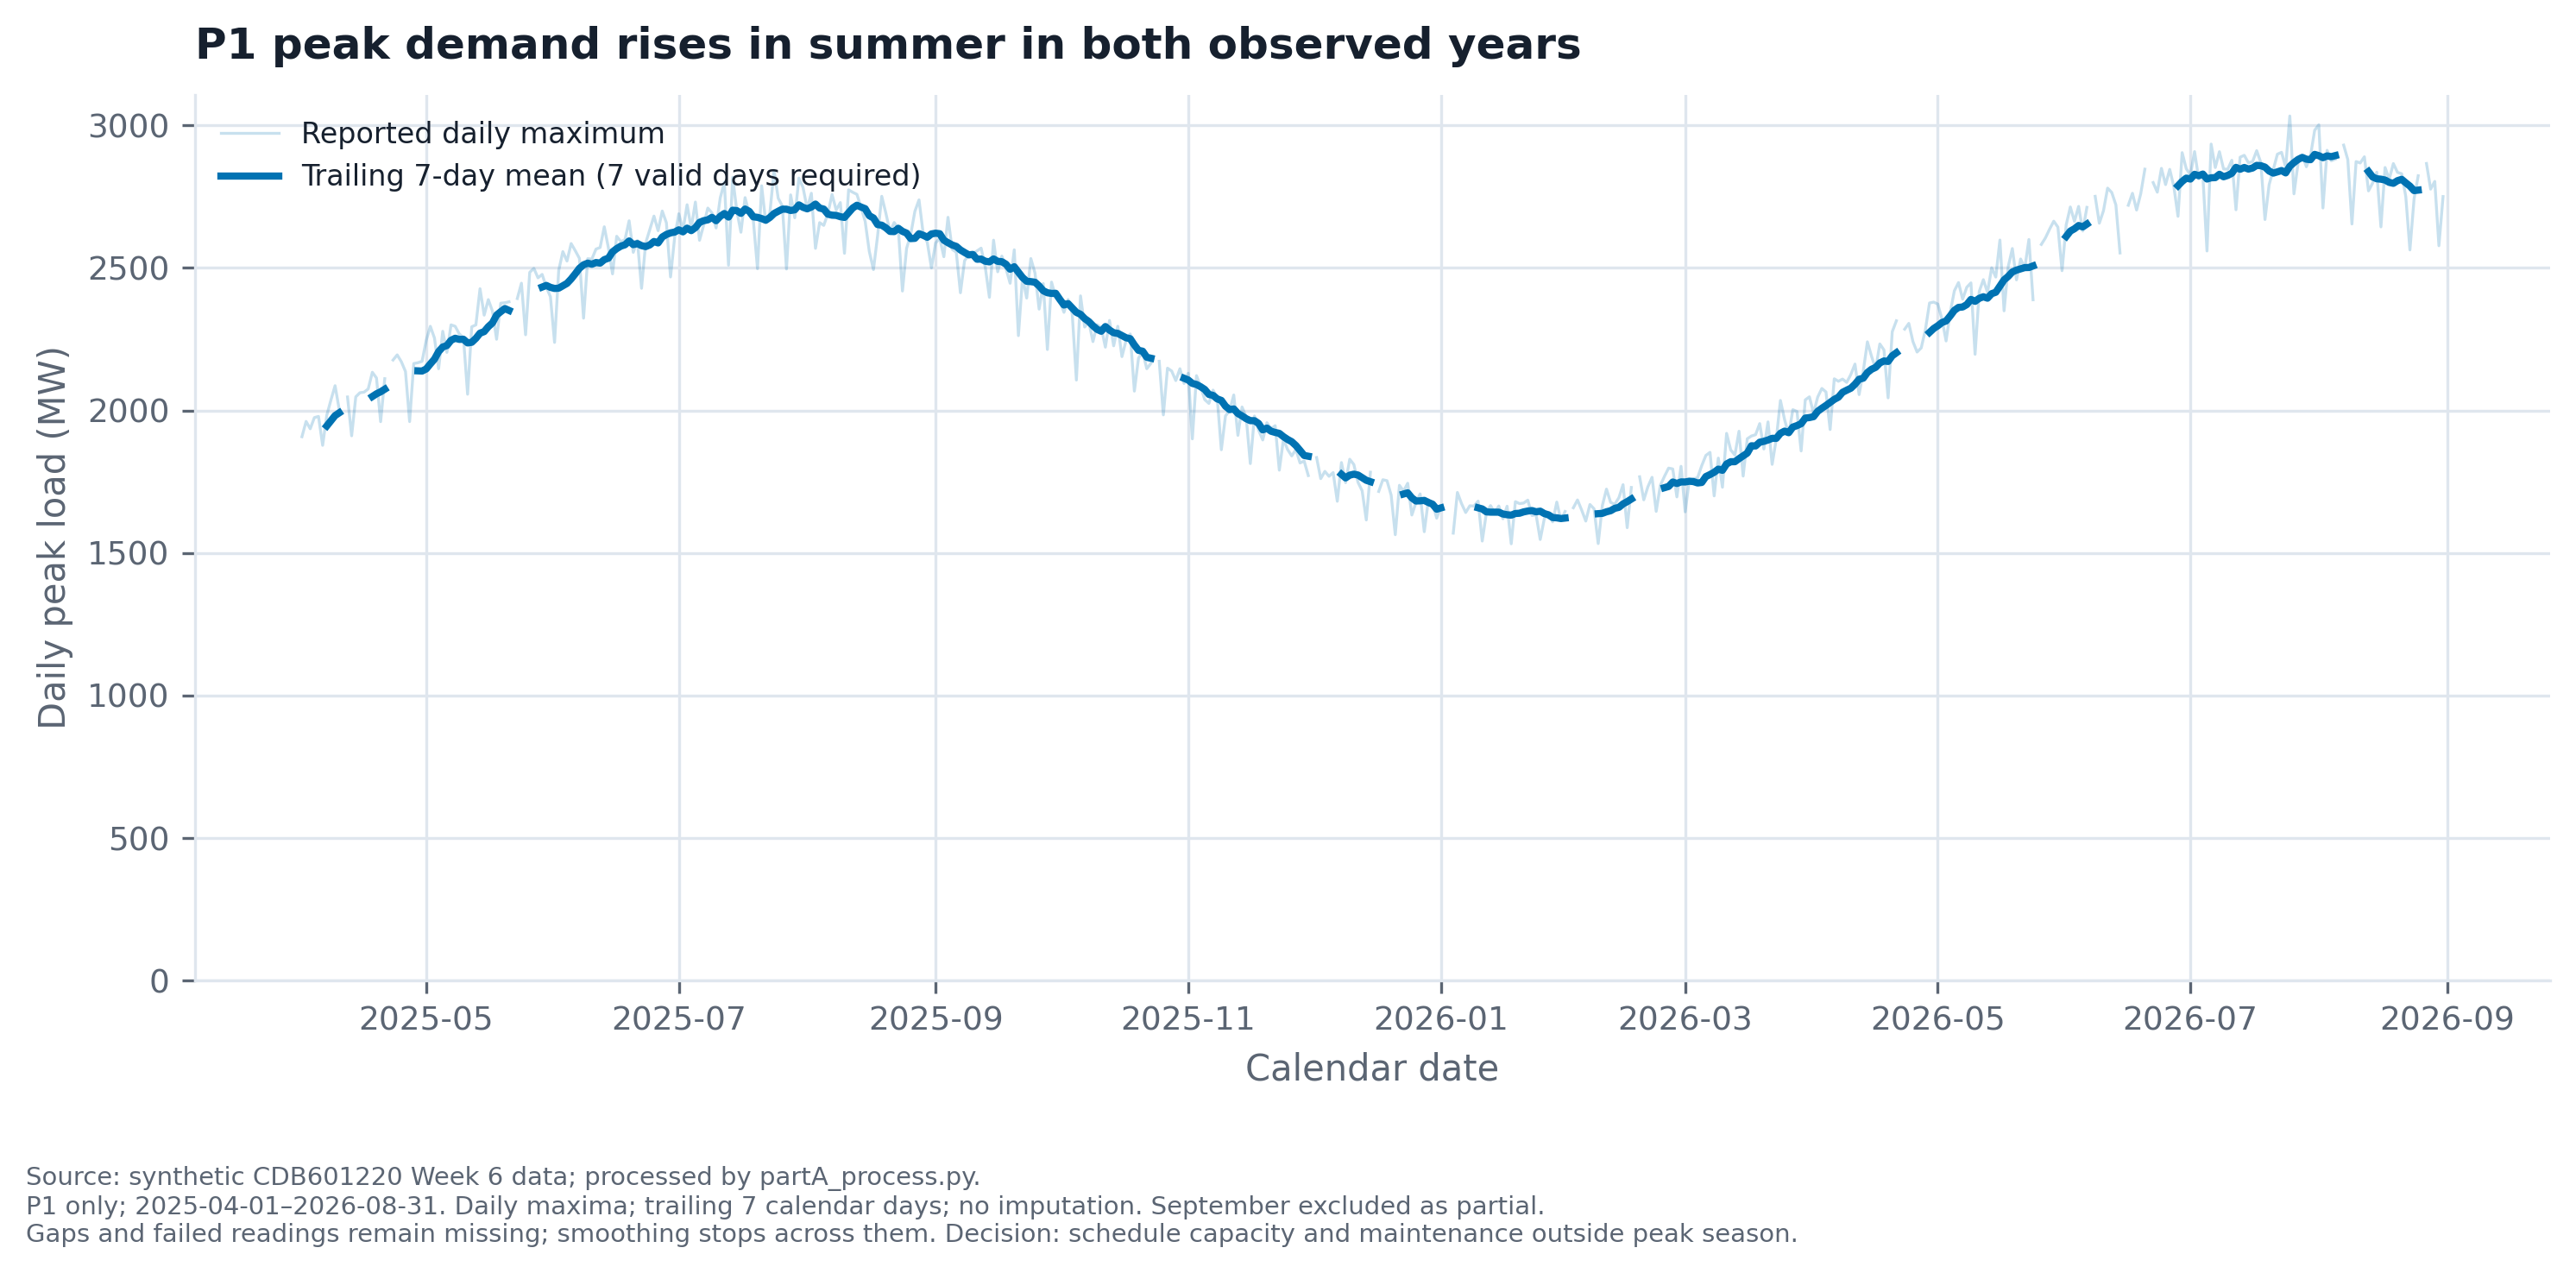

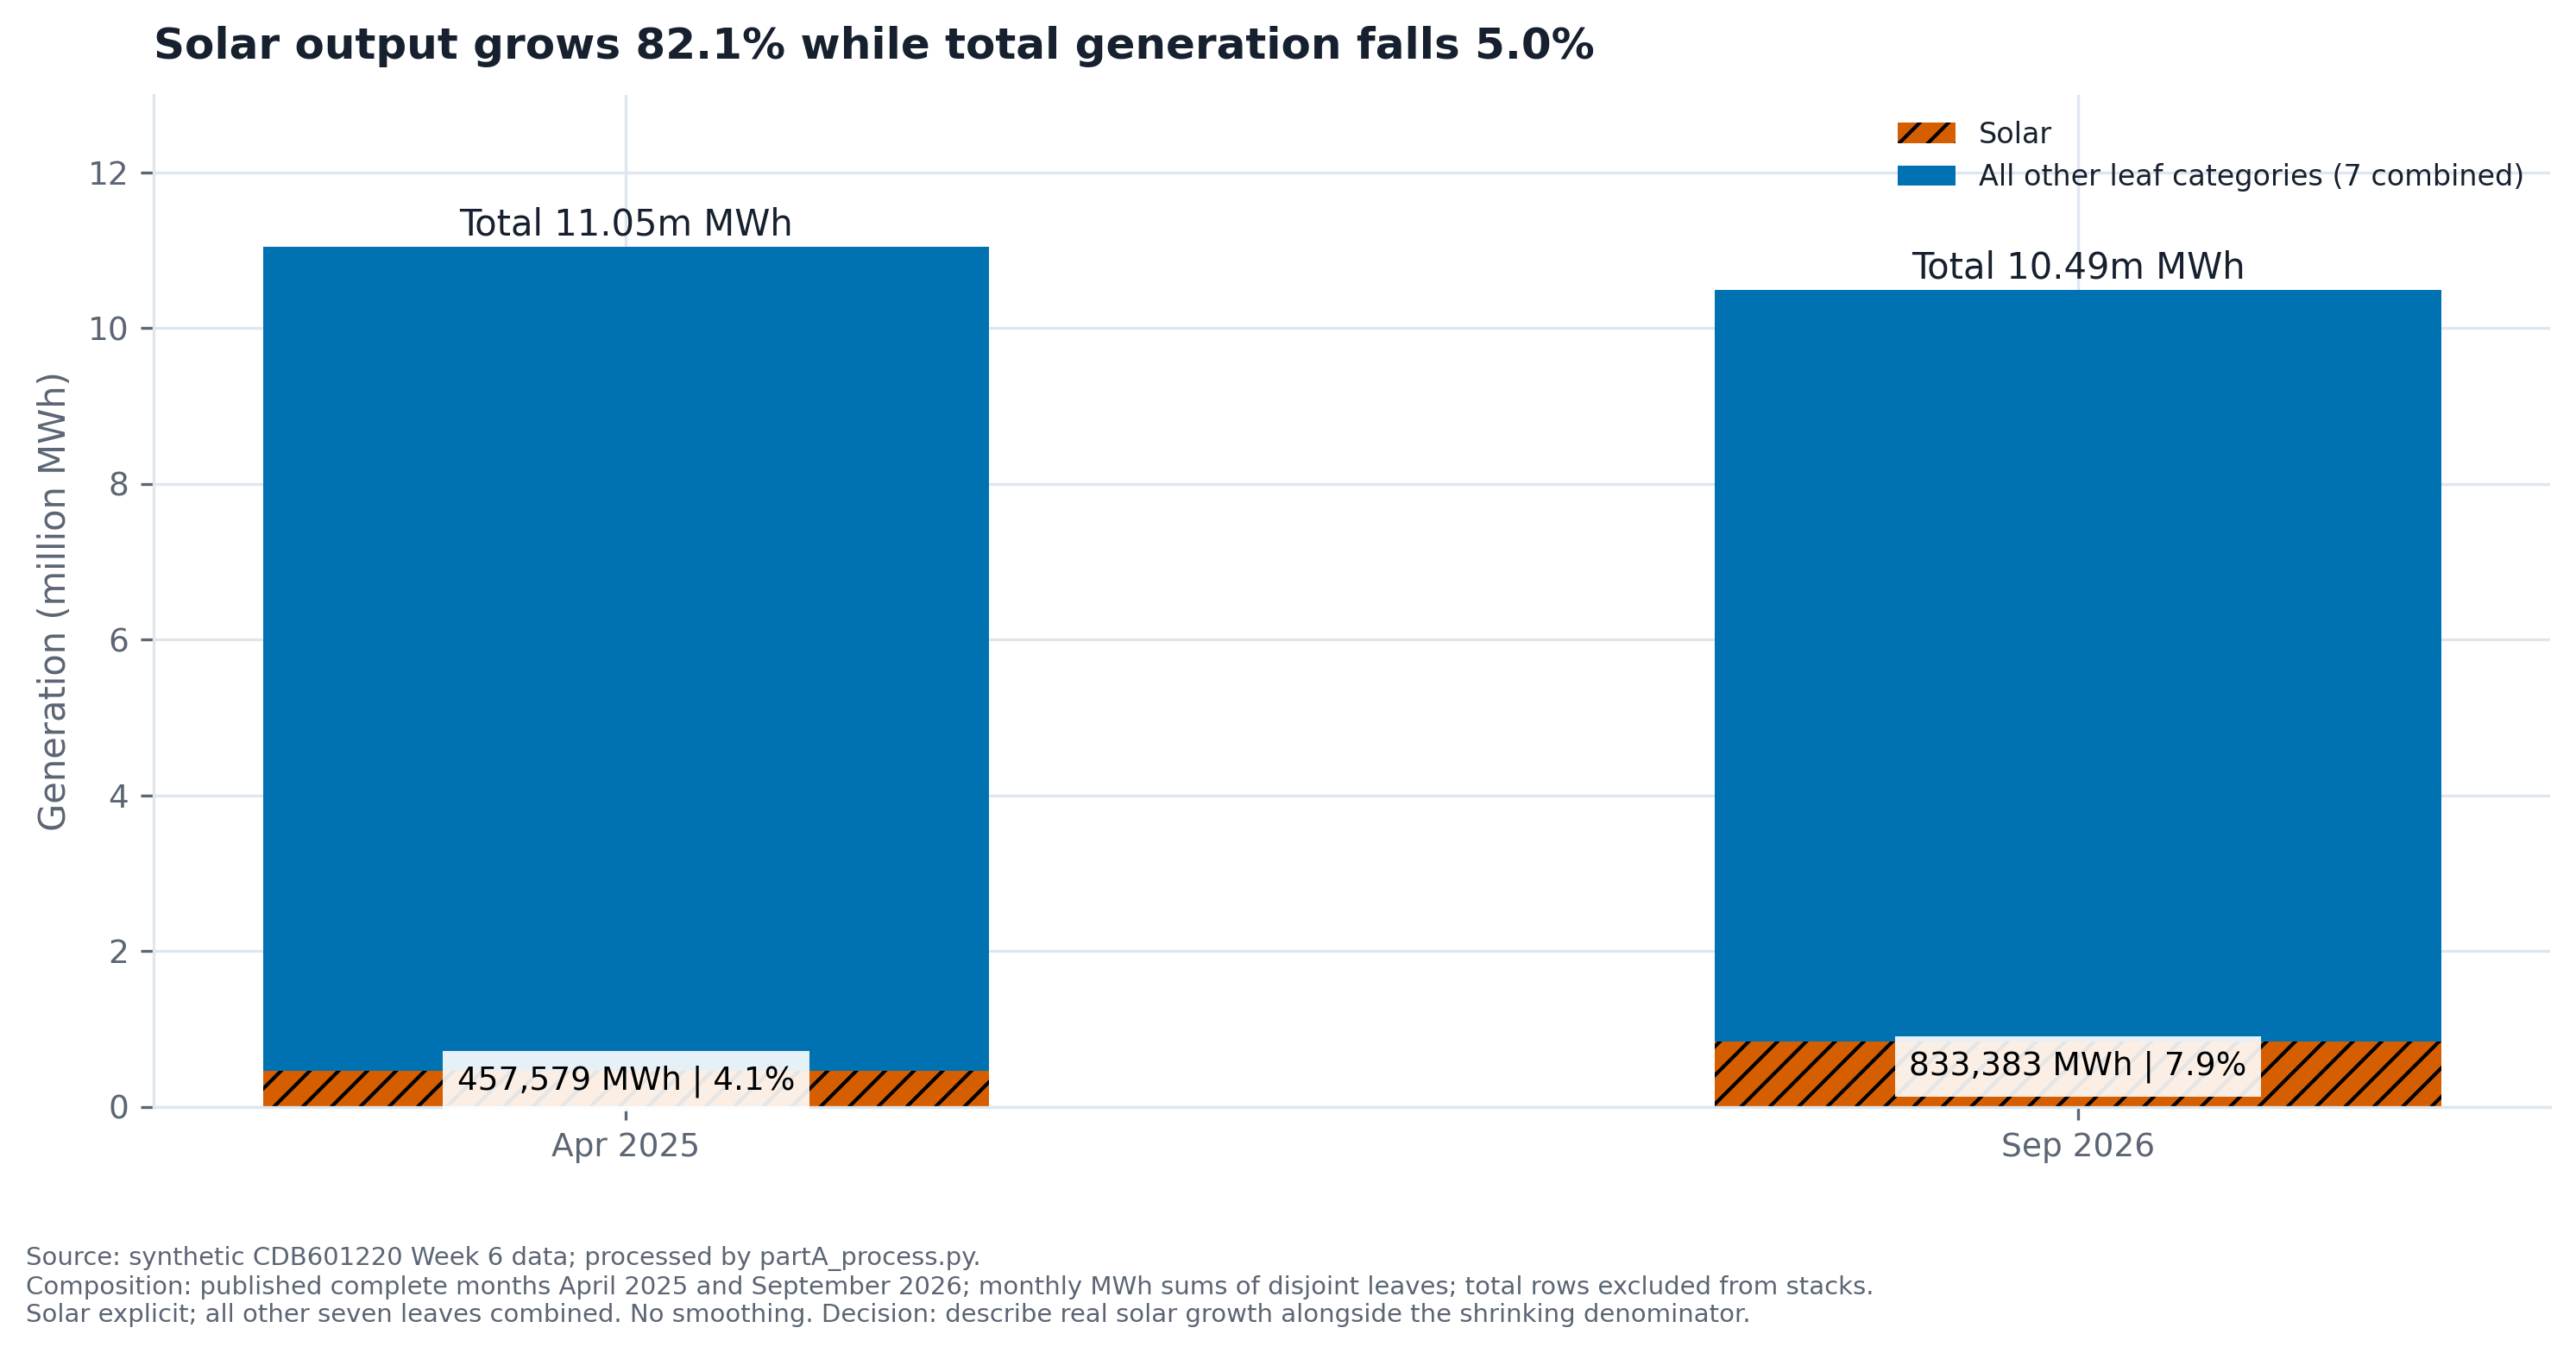

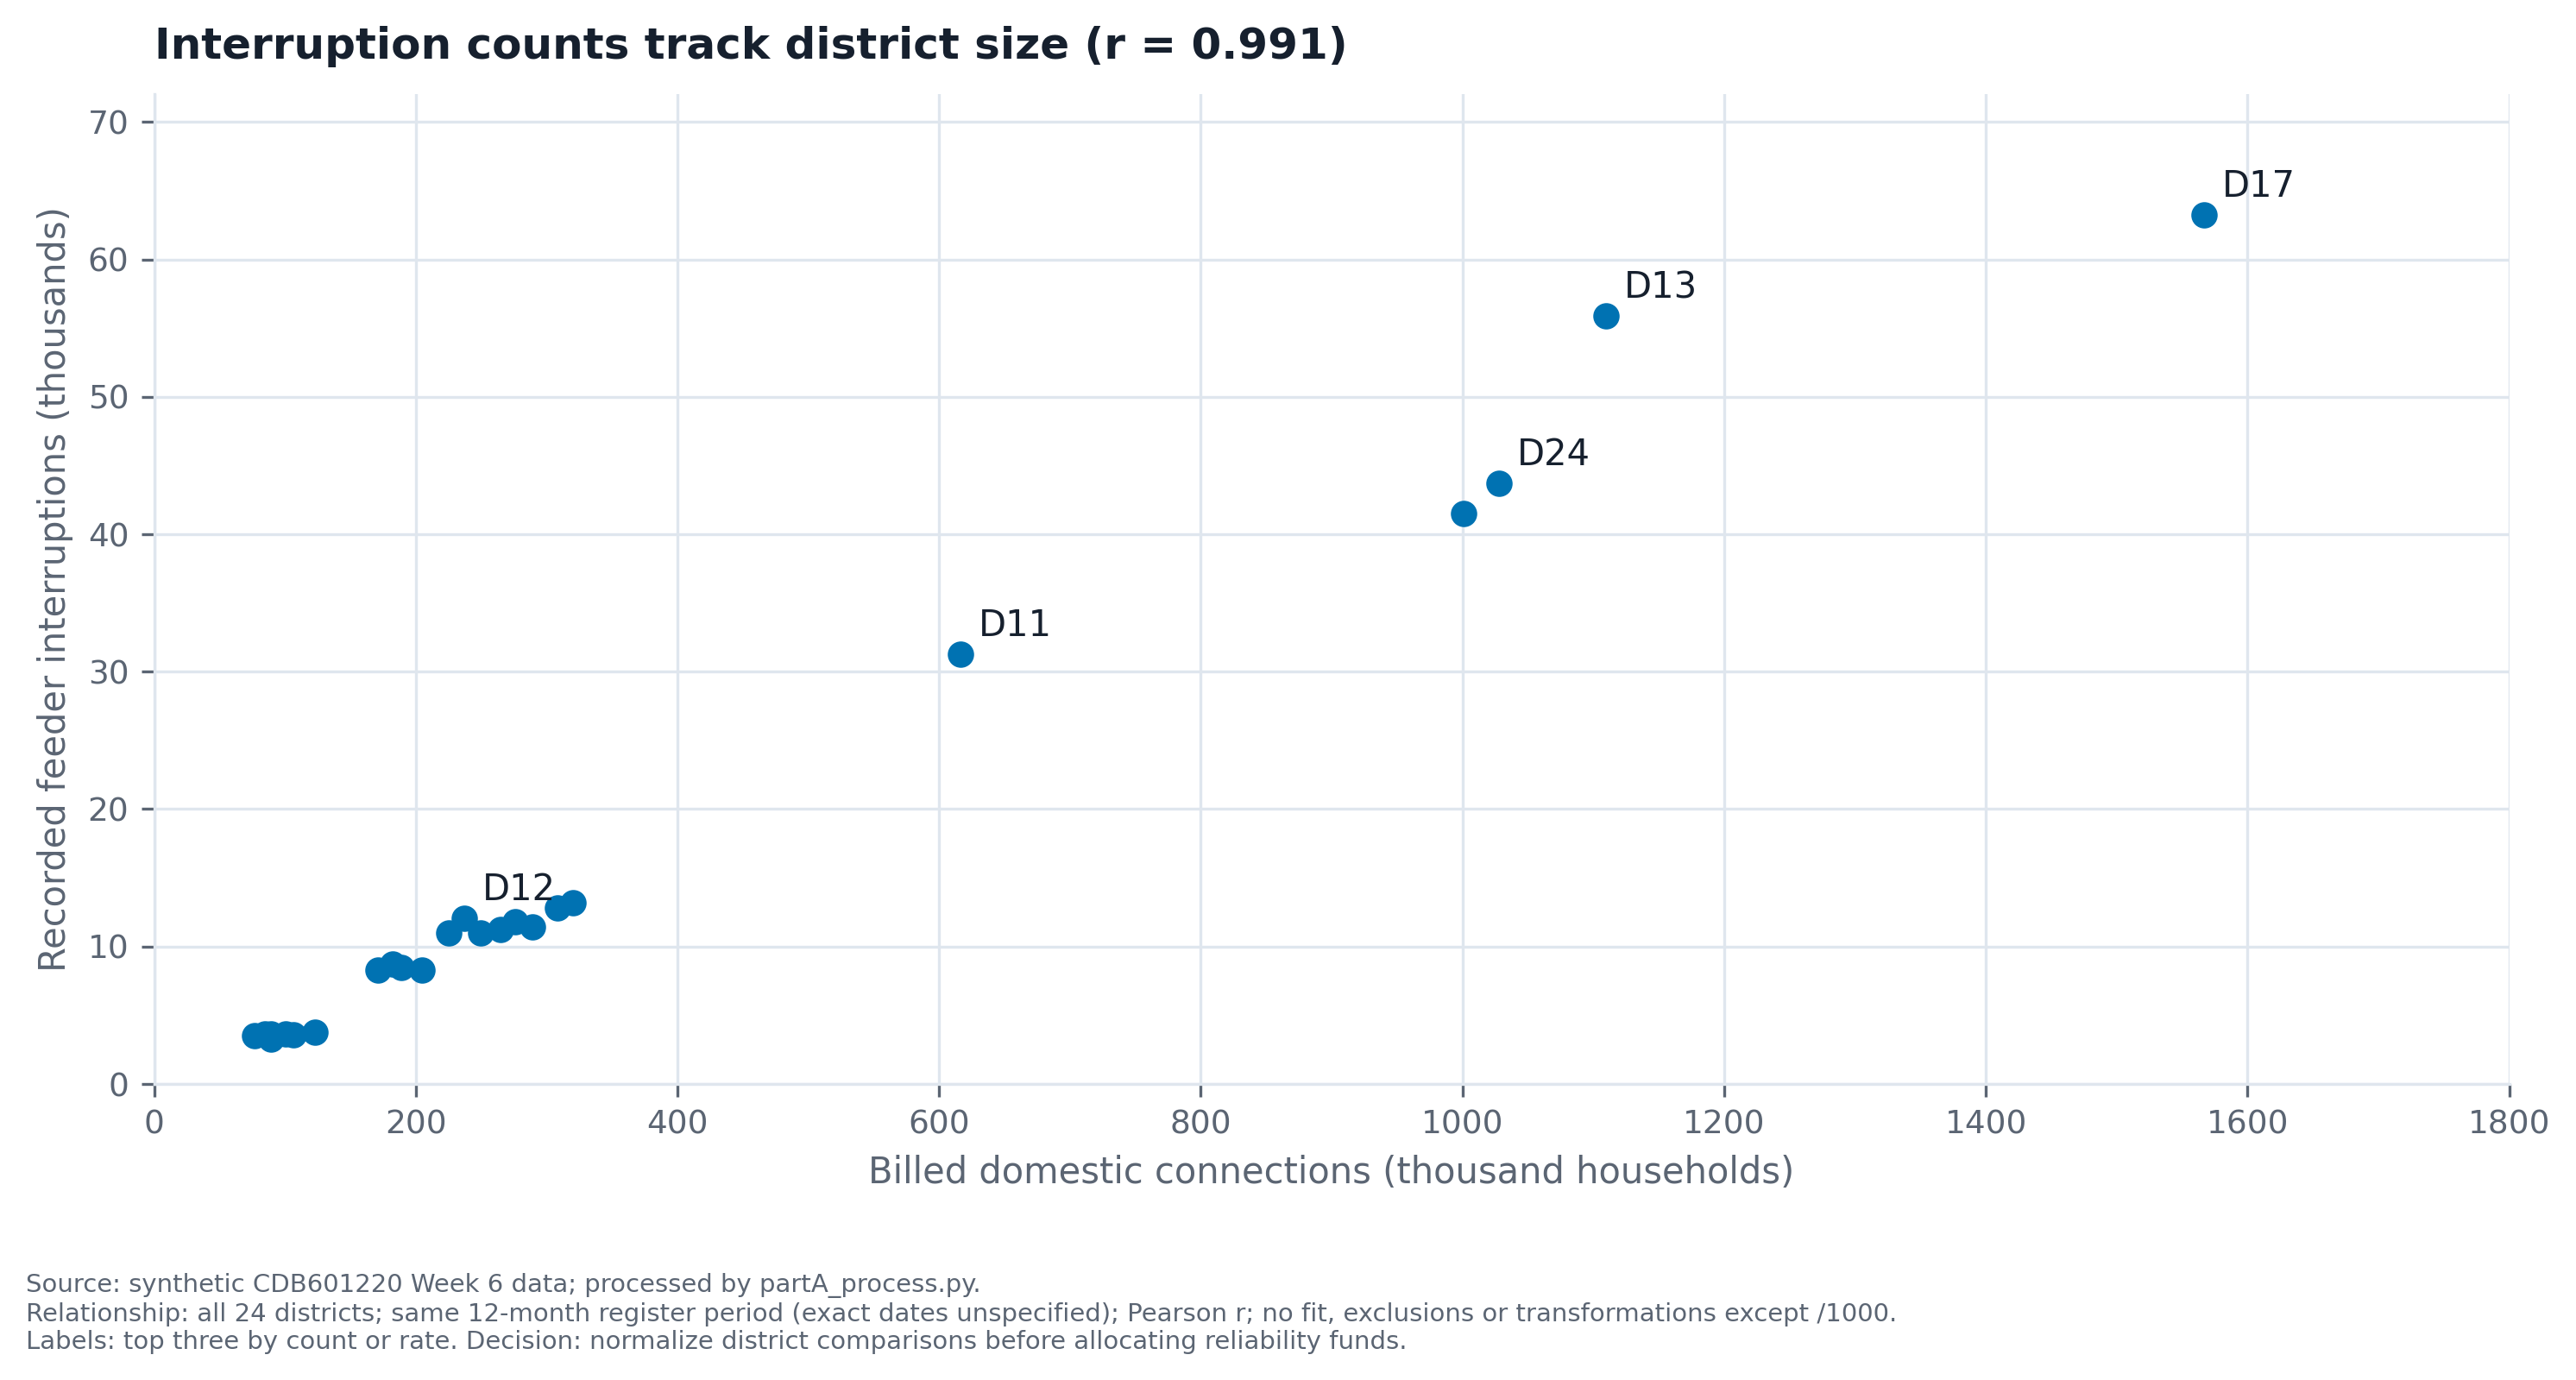

In [7]:
for n in range(1,4):
    display(Image(filename=str(ROOT/f'partB_{n}.png'), width=1000))
print((ROOT/'colour_audit.txt').read_text())

### Interpretation
The demand trend uses a real calendar axis, daily maxima and a trailing seven-day average requiring all seven observations. Missing days and failed readings break the smooth line; the partial daily September is excluded. It is not a sum of load levels or cumulative meter readings.

Solar generation increases **82.1% in absolute MWh**, while its share rises from **4.1% to 7.9%** and total generation falls **5.0%** between April 2025 and September 2026. Solar’s gain is therefore real in this synthetic generation series, although the smaller denominator amplifies its share. The generation file does not identify rooftop versus utility solar, so it cannot establish a rooftop-specific trend or prove growth across all renewable technologies.

The relationship chart shows a **+0.991** count/household correlation. Counts are useful for total burden, but the normalized rate better supports a comparison of service burden relative to district size.

## Task C — one figure for the budget board
A sorted horizontal bar chart answers where relative feeder-interruption burden is highest. Every district gets equal space and the axis names the household denominator. The exact twelve-month dates are not supplied, so none are invented.

In [8]:
__file__ = str(ROOT / 'partC_figure.py')
"""One board figure: sorted household-normalized comparison."""
from pathlib import Path
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import vizlib
ROOT=Path(__file__).resolve().parent

def main():
    d=pd.read_csv(ROOT/'clean/district_grid.csv').sort_values('interruptions_per_1000_households')
    pooled=1000*d.outages.sum()/d.households.sum();vizlib.style_defaults()
    fig,ax=plt.subplots(figsize=(10,8))
    ax.barh(d.code+'  '+d.district,d.interruptions_per_1000_households,color='#0072B2',height=.7)
    ax.axvline(pooled,color='#16202E',ls='--',lw=1.3,label=f'Pooled national rate: {pooled:.1f}')
    for y,(_,r) in enumerate(d.iterrows()):
        ax.text(r.interruptions_per_1000_households+.35,y,f'{r.interruptions_per_1000_households:.1f}',va='center',fontsize=8)
    ax.set_xlim(0,59);ax.set_xlabel('Recorded feeder interruptions per 1,000 billed domestic connections (households)')
    ax.set_title('Prioritize D12, D11 and D13 for reliability review',fontsize=15,pad=36)
    ax.text(0,1.025,'Reader: National Grid Authority budget board • D13 combines high burden with high rate',transform=ax.transAxes,fontsize=10)
    ax.grid(axis='y',visible=False);ax.legend(loc='lower right');fig.tight_layout()
    vizlib.save_fig(fig,ROOT/'partC_figure.png','Source: synthetic CDB601220 Week 6 district register; cleaned by partA_process.py. All 24 districts; same 12-month register window.\nRate = interruptions ÷ billed domestic connections × 1,000. Descending rank from top; linear zero baseline; no suppression or imputation of interruptions.\nFeeder-event rate is a comparative proxy, not household interruption frequency (SAIFI); denominator is all billed domestic connections.')
    plt.close(fig)
    note=f"""# Task C — note to the budget board

Reader: National Grid Authority reliability-budget board. Message: prioritize D12 (Lashkar), D11 (Kotla), and D13 (Mehrabad) for reliability review because their feeder interruptions per 1,000 billed domestic connections are highest.

The figure divides the same twelve-month interruption count by billed domestic connections (households) and multiplies by 1,000. This compares recorded feeder-event burden relative to service size; it does not estimate interruptions experienced by each customer or SAIFI, because affected-customer counts are unavailable. The pooled benchmark is {pooled:.1f}, computed from sums, not an average of district rates. No further electrification adjustment is applied: the denominator already describes billed connections, and three electrification percentages are missing.

A horizontal bar chart gives every district equal visual space; the five largest populations contain 59.9% of people in only 12.6% of land. Rates are ordered descending, drawn on a linear zero baseline and labelled numerically. The single blue hue has no categorical meaning, while the national benchmark uses a labelled dashed line. There are no bins, class breaks, map projection, nonlinear scaling, smoothing, or exclusions. All 24 districts remain. The source supplies a common twelve-month period but no precise district-period dates, so those dates are not invented. No district is suppressed: this is an illustrative descriptive ranking, not an inferential claim about precise causal risk.

Counterfactual: raw counts would select D17 (Qilabad), D13 (Mehrabad), and D24 (Zhobara). Only D13 appears in both lists. Count-led allocation would direct attention away from D12 and D11 toward larger D17 and D24. Count correlates with household size at +0.991; rate correlates at only +0.175. D13 has both a large connection base and a high relative interruption burden; its income is also jointly lowest at $2,600 per person/year (shared with D22). This makes its overlap an equity concern, although income association does not prove causation. A final budget should consider engineering costs and affected customers alongside this screening figure.
"""
    (ROOT/'partC_note.md').write_text(note)
    print('Task C: board figure and note written.')
if __name__=='__main__':main()


Task C: board figure and note written.


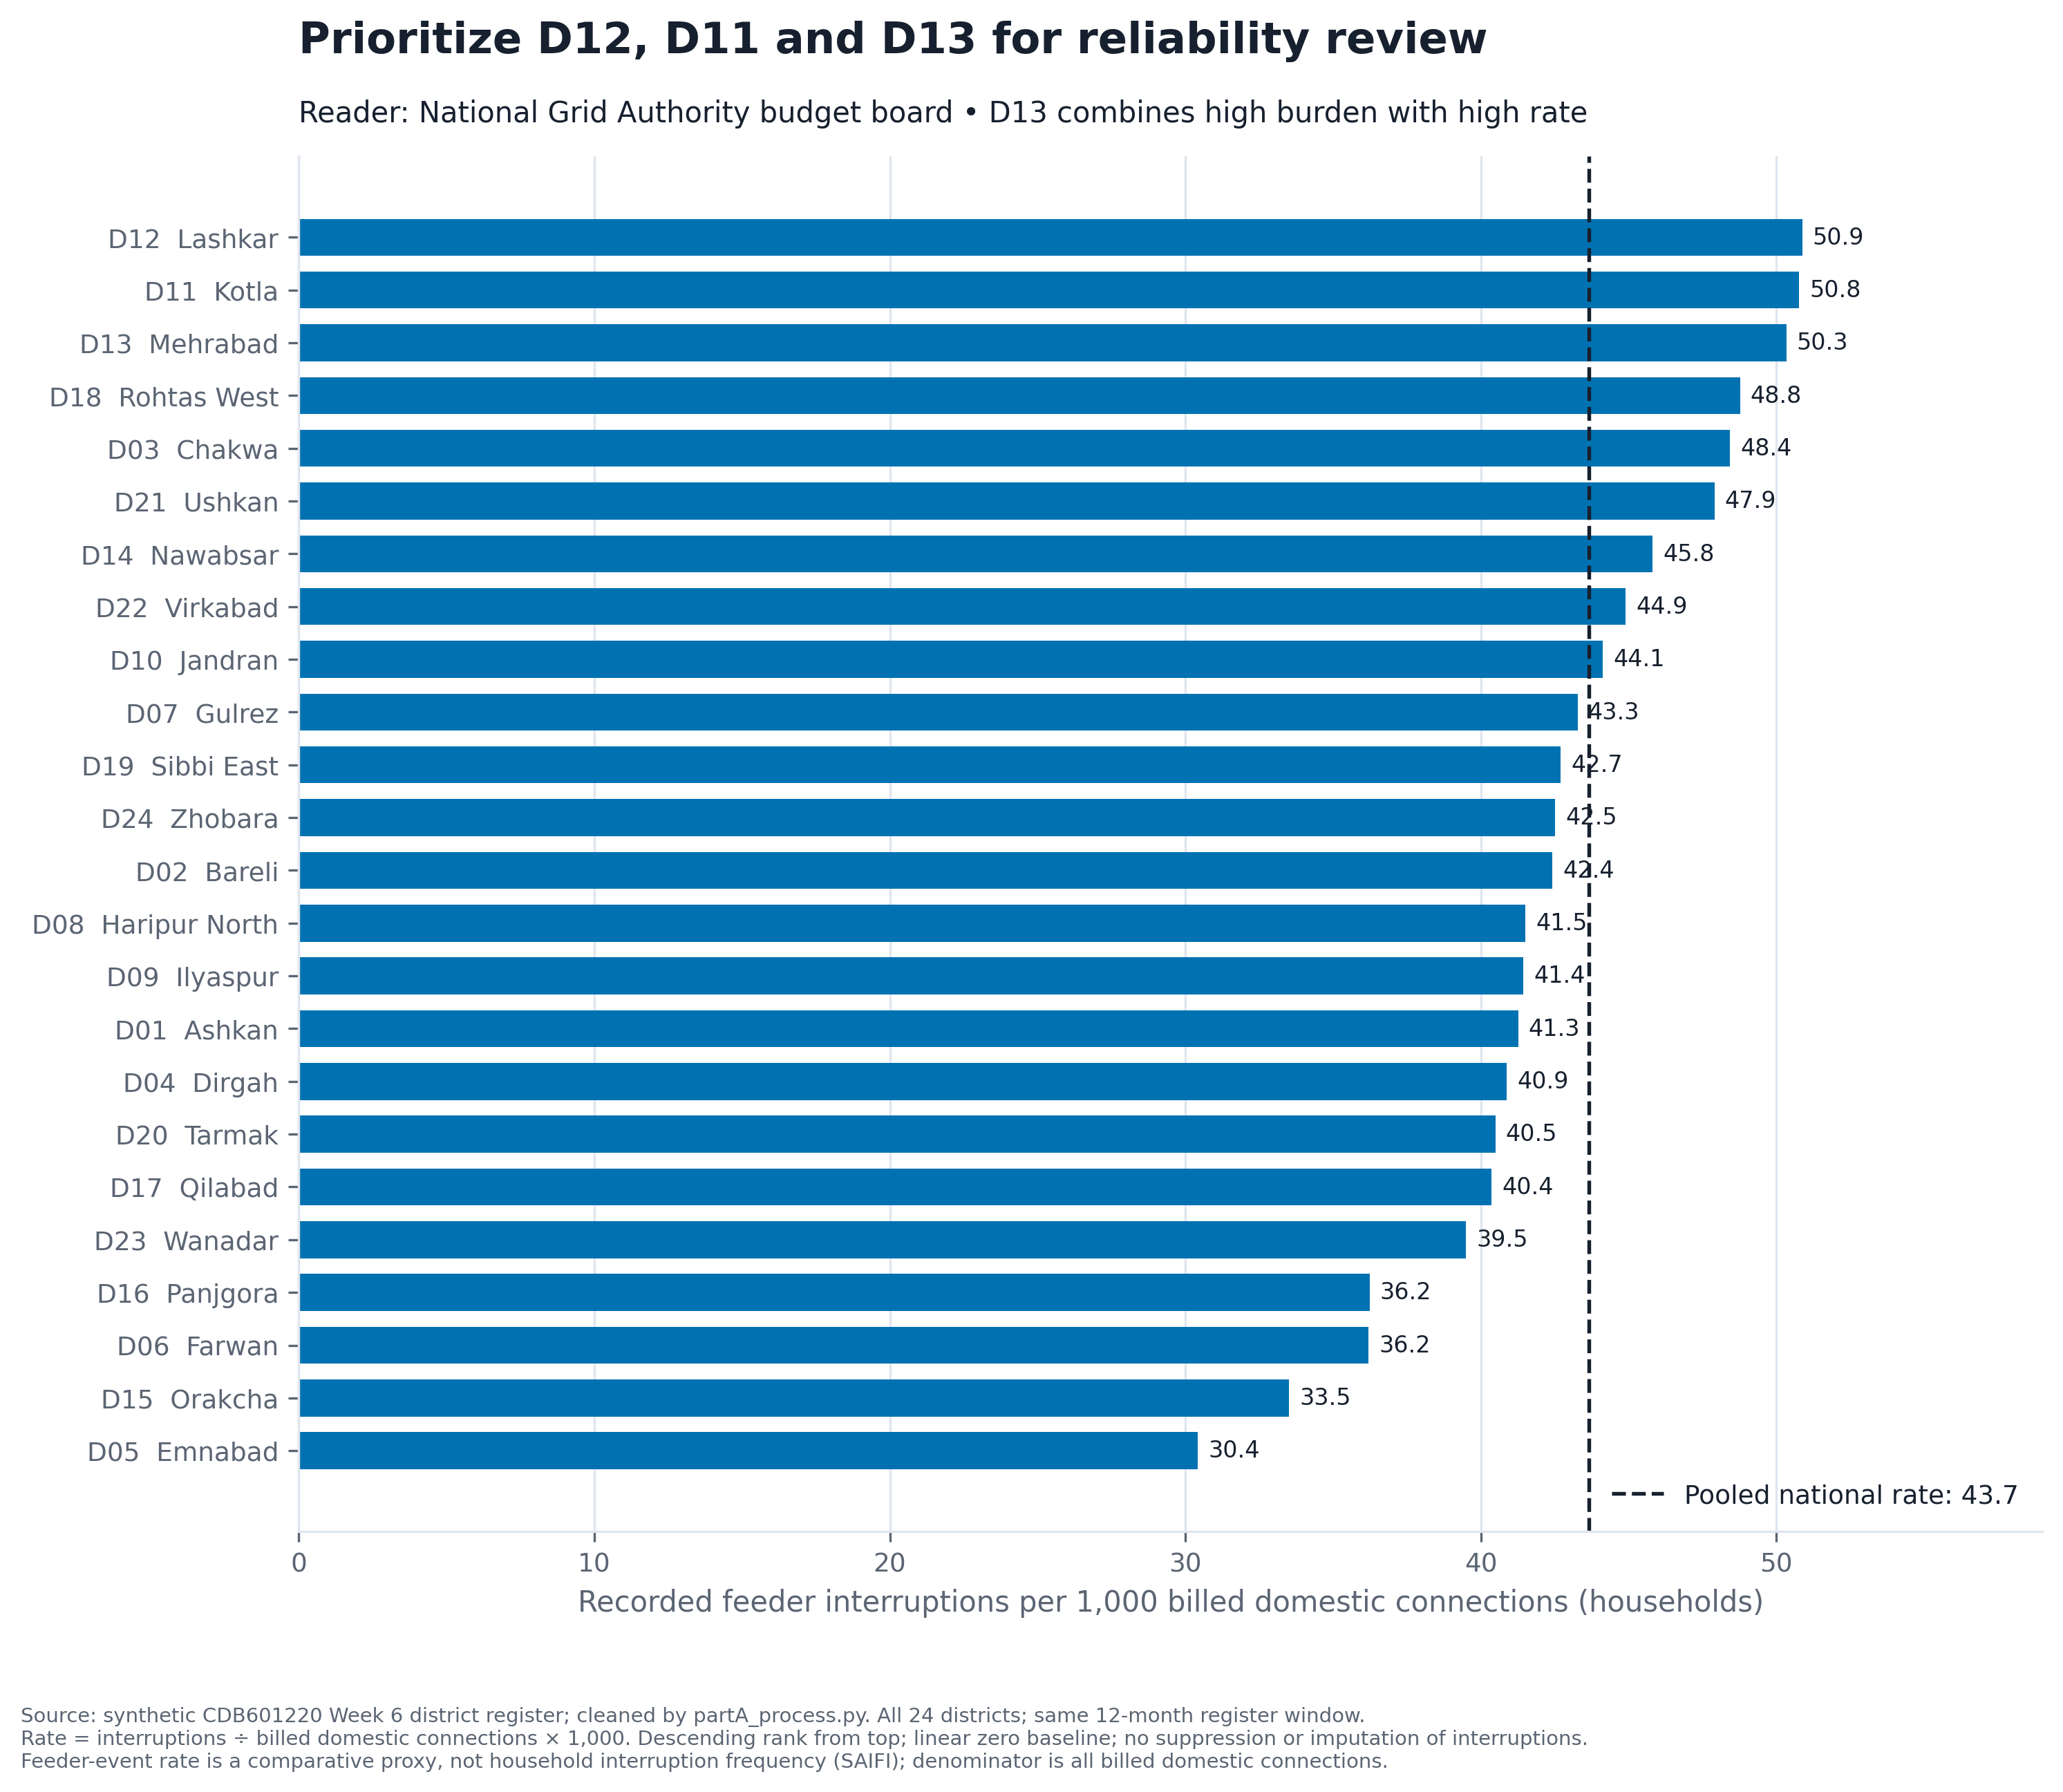

# Task C — note to the budget board

Reader: National Grid Authority reliability-budget board. Message: prioritize D12 (Lashkar), D11 (Kotla), and D13 (Mehrabad) for reliability review because their feeder interruptions per 1,000 billed domestic connections are highest.

The figure divides the same twelve-month interruption count by billed domestic connections (households) and multiplies by 1,000. This compares recorded feeder-event burden relative to service size; it does not estimate interruptions experienced by each customer or SAIFI, because affected-customer counts are unavailable. The pooled benchmark is 43.7, computed from sums, not an average of district rates. No further electrification adjustment is applied: the denominator already describes billed connections, and three electrification percentages are missing.

A horizontal bar chart gives every district equal visual space; the five largest populations contain 59.9% of people in only 12.6% of land. Rates are ordered descending, drawn on a linear zero baseline and labelled numerically. The single blue hue has no categorical meaning, while the national benchmark uses a labelled dashed line. There are no bins, class breaks, map projection, nonlinear scaling, smoothing, or exclusions. All 24 districts remain. The source supplies a common twelve-month period but no precise district-period dates, so those dates are not invented. No district is suppressed: this is an illustrative descriptive ranking, not an inferential claim about precise causal risk.

Counterfactual: raw counts would select D17 (Qilabad), D13 (Mehrabad), and D24 (Zhobara). Only D13 appears in both lists. Count-led allocation would direct attention away from D12 and D11 toward larger D17 and D24. Count correlates with household size at +0.991; rate correlates at only +0.175. D13 has both a large connection base and a high relative interruption burden; its income is also jointly lowest at $2,600 per person/year (shared with D22). This makes its overlap an equity concern, although income association does not prove causation. A final budget should consider engineering costs and affected customers alongside this screening figure.


In [9]:
display(Image(filename=str(ROOT/'partC_figure.png'), width=1000))
display(Markdown((ROOT/'partC_note.md').read_text()))

## Task D1 — interactive bonus
An offline Plotly version of Task B’s trend supports date/value inspection, trace toggling and date-range zoom. The note names both the benefit and the risk of cherry-picking.

In [10]:
__file__ = str(ROOT / 'partD_interactive.py')
"""Bonus D1: interactive counterpart of Task B's P1 time trend."""
from pathlib import Path
import pandas as pd
import plotly.graph_objects as go
ROOT=Path(__file__).resolve().parent

def main():
    g=pd.read_csv(ROOT/'clean/grid_daily.csv',parse_dates=['date'])
    s=g[g.zone=='P1'].set_index('date').peak_load_mw.reindex(pd.date_range('2025-04-01','2026-08-31'))
    fig=go.Figure()
    fig.add_trace(go.Scatter(x=s.index,y=s,mode='lines',line=dict(color='#0072B2',width=1),opacity=.35,name='Daily maximum',connectgaps=False))
    fig.add_trace(go.Scatter(x=s.index,y=s.rolling(7,min_periods=7).mean(),mode='lines',line=dict(color='#0072B2',width=3),name='Trailing 7-day mean',connectgaps=False))
    fig.update_layout(title='P1 demand rises in summer | hover or zoom to inspect',template='plotly_white',height=620,yaxis=dict(title='Peak load (MW)',rangemode='tozero'),xaxis=dict(title='Calendar date',rangeslider=dict(visible=True)),hovermode='x unified',margin=dict(b=170),annotations=[dict(x=0,y=-.33,xref='paper',yref='paper',showarrow=False,align='left',text='Source: synthetic CDB601220 Week 6; P1, Apr 2025–Aug 2026; September omitted as partial.<br>Daily maximum and trailing 7 calendar-day mean (7 valid readings); no imputation; gaps unconnected.<br>Decision: plan capacity around seasonal demand; compare complete seasons before drawing conclusions.')])
    fig.write_html(ROOT/'partD_interactive.html',include_plotlyjs=True,full_html=True)
    (ROOT/'partD_note.md').write_text('# Bonus D1\n\nInteraction lets the reader hover exact dates and values, toggle the raw or smoothed trace, and zoom into a season, which the static overview cannot do.\n\nIt also lets a reader cherry-pick a short interval or hide context to exaggerate a trend, so seasonal claims should use the complete initial date range.\n\nThe HTML embeds Plotly and works offline; missing values remain gaps.\n')
    print('Task D1: standalone offline interactive HTML written.')
if __name__=='__main__':main()


Task D1: standalone offline interactive HTML written.


In [11]:
display(Markdown((ROOT/'partD_note.md').read_text()))
print('Open partD_interactive.html in a browser; Plotly is embedded and no internet is required.')

Open partD_interactive.html in a browser; Plotly is embedded and no internet is required.


# Bonus D1

Interaction lets the reader hover exact dates and values, toggle the raw or smoothed trace, and zoom into a season, which the static overview cannot do.

It also lets a reader cherry-pick a short interval or hide context to exaggerate a trend, so seasonal claims should use the complete initial date range.

The HTML embeds Plotly and works offline; missing values remain gaps.


## Final reproducibility checks
The raw inputs must remain byte-identical, all four required exported figures must have 300 dpi metadata, and the notebook must finish without cell errors. Re-running regenerates cleaned files and figures from the raw inputs. The complete ZIP also includes original instructions, scripts, dependencies, audits, conflict candidates, missing-day keys and the interactive bonus.

In [12]:
from PIL import Image as PILImage
assert raw_hashes == {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in (ROOT/'data').iterdir() if p.is_file()}
for fn in ['partB_1.png','partB_2.png','partB_3.png','partC_figure.png']:
    with PILImage.open(ROOT/fn) as img:
        dpi = img.info.get('dpi')
        assert dpi and all(abs(x-300)<1 for x in dpi)
        print(fn, img.size, 'DPI:', dpi)
print('Raw inputs unchanged. All required outputs generated. All checks passed; published energy discrepancy documented.')

partB_1.png (2985, 1475) DPI: (299.9994, 299.9994)
partB_2.png (2985, 1568) DPI: (299.9994, 299.9994)
partB_3.png (2985, 1599) DPI: (299.9994, 299.9994)
partC_figure.png (2985, 2593) DPI: (299.9994, 299.9994)
Raw inputs unchanged. All required outputs generated. All checks passed; published energy discrepancy documented.
